# 04 - Tactics in critical positions, by Elo (+ unforced errors)

Order of work:
1. **Time control** - the earlier analysis had **no** time-control filter (only `min_elo`), and the CSV did not store the TimeControl. Here we read it back from the PGN and filter on the increment (default: +3 s per move, so time trouble is not the explanation for mistakes).
2. **Tactic labels** for every critical position (Stockfish, resumable): which tactic the best move realises (*missed*) and which tactic the opponent gets after a mistake (*allowed*).
3. **Results**: blunder rate per tactic and Elo, share of mistakes that the rules can classify, review sample for checking the rules by hand.
4. **Unforced errors**: positions with a second good move where the player still loses more than the blunder threshold.

All rates are shown as **blunder rate = 1 - share of best moves found**, with 95% confidence intervals.

> All of this code was written without being run on real data. Start every long step with a small `max_rows` / `sample_n` to check that it works.

In [1]:
# Windows + Jupyter: without this python-chess cannot start the engine (NotImplementedError)
import asyncio, sys
if sys.platform == "win32":
    asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())

import sys
sys.path.append('../src')

import importlib
import pandas as pd
import matplotlib.pyplot as plt

import critical, timecontrol, enrich, tactic_stats as S
for m in (critical, timecontrol, enrich, S):
    importlib.reload(m)

ENGINE_PATH = '../chess-features-thesis/stockfish/stockfish-windows-x86-64-universal.exe'
ENGINE_PATH =r"C:\Users\him3c\Documents\Praca magisterska\chess-features-thesis\stockfish\stockfish-windows-x86-64-universal.exe"
PGN_PATH    = '../data/lichess_db_standard_rated_2026-08.pgn.zst'       # the SAME file the games were taken from
MAIN_CSV    = '../data/critical_positions.csv'
REGISTRY    = '../data/analysed_games.csv'
ENRICHED    = '../data/critical_tacticsnew.csv'
UNFORCED    = '../data/unforced_errors.csv'

# if the path above is wrong, look for any .exe in the engine/ folder (also in sub-folders)
import glob, os
if not os.path.exists(ENGINE_PATH):
    found = glob.glob('../engine/**/*.exe', recursive=True)
    if found:
        ENGINE_PATH = found[0]
print('engine:', os.path.abspath(ENGINE_PATH), '| exists:', os.path.exists(ENGINE_PATH))

INCREMENT = 3                                       # seconds per move; None = no time-control filter
BINS   = [0, 1200, 1600, 2400, 4000]
LABELS = ['<1200', '1200-1600', '1600-2400', '2400+']

engine: C:\Users\him3c\Documents\Praca magisterska\chess-features-thesis\stockfish\stockfish-windows-x86-64-universal.exe | exists: True


## 1. Time control
**Was there a filter before? No.** `find_critical_positions` only had `min_elo`; the games in `critical_positions.csv` are a mix of all time controls. The cell below reads the `TimeControl` header of every analysed game from the PGN (matching games by their index in the file, like the registry backfill) and adds the columns `time_control`, `base_seconds`, `increment` to the CSV (a copy is kept as `critical_positions.csv.bak_tc`). Run it **once**; it is safe to repeat.

In [ ]:
df_all = timecontrol.tag_time_control(PGN_PATH, MAIN_CSV)
timecontrol.time_control_report(df_all)

How many analysed games already have the wanted increment? If it is too few, continue collecting - from now on every analysis function has an `increment=` parameter (new rows also store `time_control` and `increment`), e.g.:

In [ ]:
games = df_all.drop_duplicates('game_id')
print(f"games with increment {INCREMENT}: {(games['increment'] == INCREMENT).sum()} of {len(games)}")

### Collect more games - only with the chosen increment
Resumable (stop and run again any time); games already in the registry are skipped, new rows store `time_control` and `increment`. Quotas keep the Elo bins balanced; `sample_prob < 1` spreads the sample over the whole file (see notebook 02).

In [2]:
df = critical.find_critical_positions(
    PGN_PATH,
    ENGINE_PATH,
    output_csv=MAIN_CSV,
    max_games=None,                           # None = until the quotas are full
    quota_edges=BINS,                         # Elo bins used for sampling (mean Elo of both players)
    games_per_bin=400,                        # games per bin
    depth=12,
    gap_threshold=0.20,
    min_ply=8,
    increment=INCREMENT,                      # only games with this increment (3 = +3 s per move)
    sample_prob=0.01,
    threads=4,
    save_every=10,
    max_scanned=None,                    # stop after looking at this many games of the file (None = no limit)
    progress_every=5000,                      # how often the status line (scanned / skipped and why) is refreshed
    registry_path=REGISTRY,
)
print(df.shape)

quota status at start (games with increment 3 per Elo bin, target 400): {0: 400, 1: 400, 2: 400, 3: 400}
all quotas are already full - nothing to analyse
(178006, 21)


## 2. Tactic labels (Stockfish) - resumable
For every **critical** position (with the chosen increment):
- `missed_*`: detectors on the **best move** (+ the engine's next two plies for *elimination of the defence*),
- `allowed_*`: for **mistakes only**, detectors on the opponent's best reply after the played move (attacking tactics only),
- optional `tactic_length`: number of consecutive critical positions for the player along the engine line (1 = a single only-move; a check before the tactic makes it 2). It needs 2-5 extra searches per row, so it is off by default.

Cost: about 1 search per position that was played correctly and 2 per mistake.

In [3]:
enriched = enrich.enrich_critical(
    MAIN_CSV, ENRICHED, ENGINE_PATH,
    depth=12, increment=INCREMENT, max_rows=50000,
    compute_length=False,
    threads=4,
)
enriched.shape

0 critical positions to process


critical positions: 0it [00:00, ?it/s]


(7318, 18)

## 3. Missed tactics: how often are they found, by Elo?
Among the critical positions whose best move realises tactic *T*: **blunder rate** = share where the player did not play it. `none` = no tactic recognised (the part the rules do not explain yet).

In [4]:
data = S.load_tactic_data(MAIN_CSV, ENRICHED, REGISTRY)
print(f"{len(data)} critical positions, {(~data['found_best']).sum()} of them mistakes")
S.blunder_by_tactic(data, 'missed_tactics').sort_values('n_critical', ascending=False)

7318 critical positions, 1123 of them mistakes


,tactic,n_critical,n_found,found_rate,blunder_rate,ci_low,ci_high,blunder_ci_low,blunder_ci_high
1,capture_unprotected,3007,2821,0.938144,0.061856,0.928962,0.946208,0.053792,0.071038
9,none,2572,1994,0.775272,0.224728,0.758737,0.790986,0.209014,0.241263
5,double_attack,512,394,0.769531,0.230469,0.731126,0.803922,0.196078,0.268874
7,favourable_exchange,451,411,0.911308,0.088692,0.881477,0.934192,0.065808,0.118523
10,pin,340,286,0.841176,0.158824,0.798542,0.876187,0.123813,0.201458
0,capture_attacked_more_than_defended,328,264,0.804878,0.195122,0.758564,0.844134,0.155866,0.241436
3,defend_threatened_piece,221,160,0.723982,0.276018,0.661598,0.778712,0.221288,0.338402
6,elimination_of_defence,213,169,0.793427,0.206573,0.734093,0.842365,0.157635,0.265907
4,discovered_attack,195,146,0.748718,0.251282,0.683432,0.804394,0.195606,0.316568
2,defend_against_mate,138,129,0.934783,0.065217,0.880701,0.965313,0.034687,0.119299


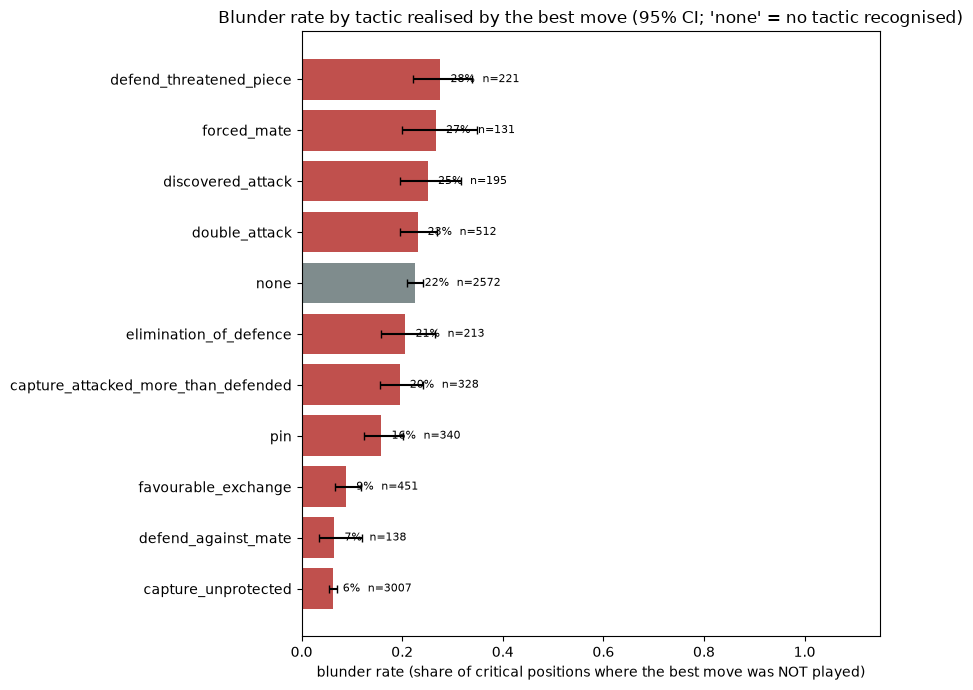

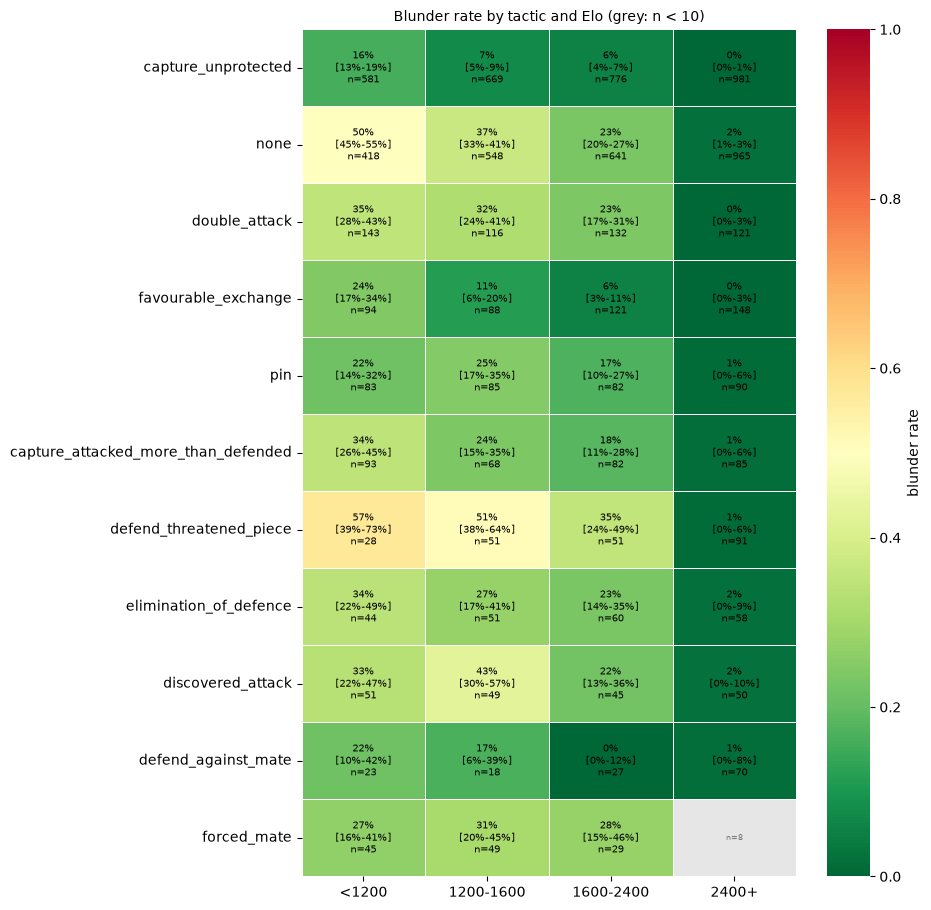

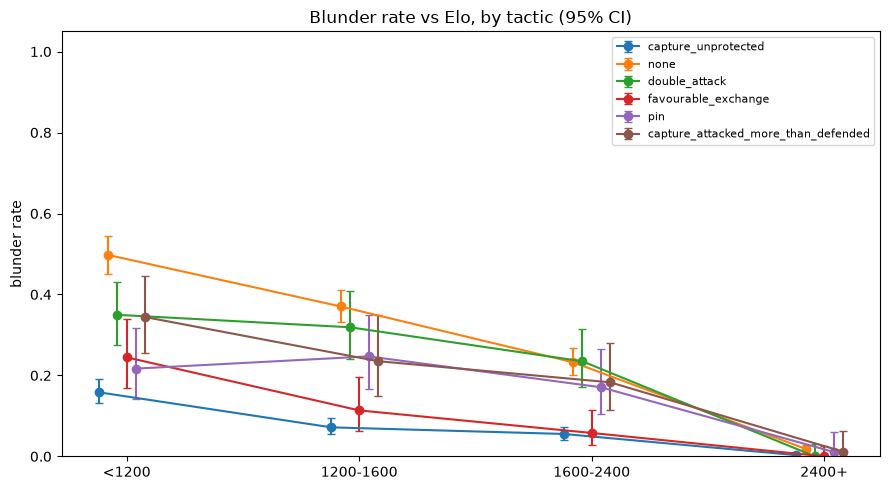

In [5]:
S.plot_tactic_blunder_rates(data, 'missed_tactics', min_n=10); plt.show()
S.plot_tactic_elo_heatmap(data, BINS, LABELS, 'missed_tactics', min_n=10); plt.show()
S.plot_tactic_elo_lines(data, BINS, LABELS, 'missed_tactics', min_n=15); plt.show()

## 4. Allowed tactics and how much the rules explain
**Allowed** = the tactic the opponent gets after the player's mistake (opponent's best reply, attacking tactics only). The second plot answers "what percentage of the mistakes did we classify?" - split into *both* (a tactic was missed **and** one was allowed), *missed only*, *allowed only* and *none*.

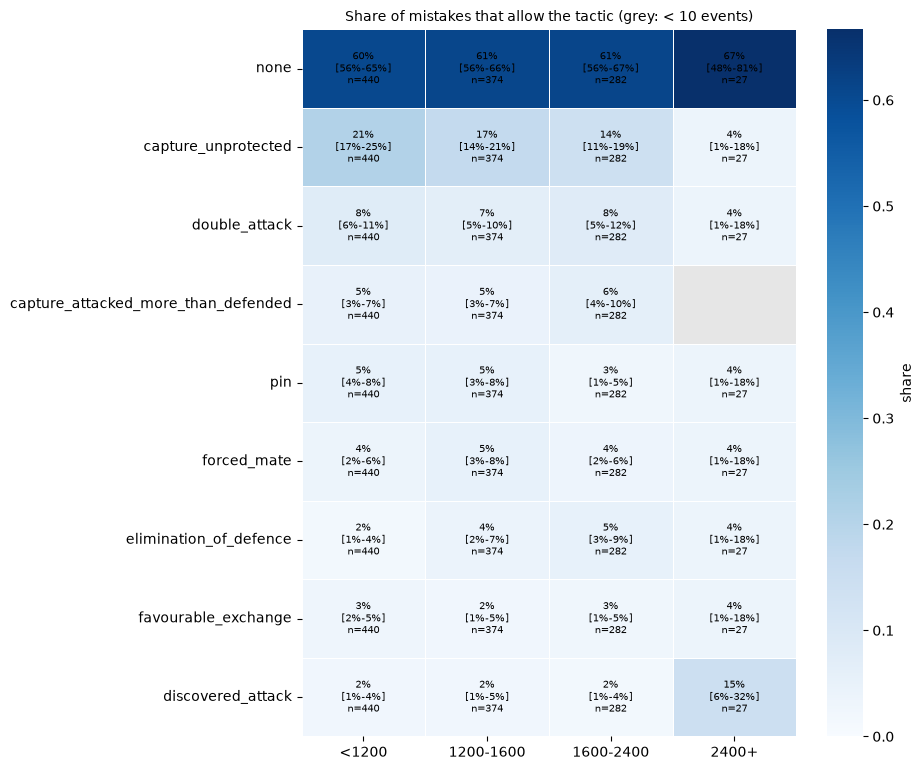

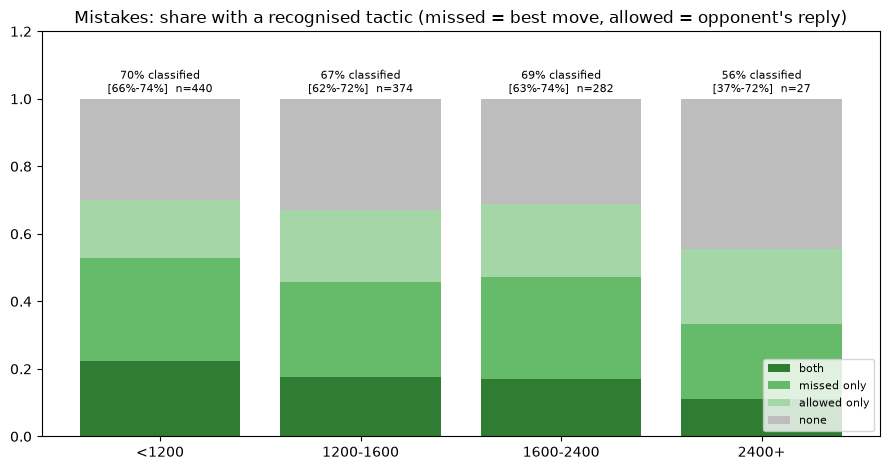

class,both,missed only,allowed only,none,total,classified,classified_share,ci_low,ci_high
elo_bin,,,,,,,,,
<1200,98,134,76,132,440,308,0.700,0.656,0.741
1200-1600,66,105,80,123,374,251,0.671,0.622,0.717
1600-2400,48,85,61,88,282,194,0.688,0.632,0.739
2400+,3,6,6,12,27,15,0.556,0.373,0.724


In [6]:
mistakes = data[~data['found_best']]
S.plot_share_heatmap(mistakes, BINS, LABELS, 'allowed_tactics', title='Share of mistakes that allow the tactic'); plt.show()
S.plot_classified_share(mistakes, BINS, LABELS); plt.show()
S.classified_table(mistakes, BINS, LABELS).round(3)

## 4b. Whose tactic and how long
For every tactical mistake: **(a)** the type (`missed_tactics` / `allowed_tactics`), **(b)** whose tactic it is - `player` (the best move would have realised it), `opponent` (the played move gives it away) or `both`, **(c)** its **length** = number of consecutive critical positions for the player along the engine line (1 = one only-move; 2 = a preparatory forcing move, e.g. a check, comes first).

`tactic_length` costs 1-5 extra searches per row, so it is filled for rows that already have a label, `max_rows` at a time (resumable)

In [7]:
enriched = enrich.add_tactic_length(
    MAIN_CSV, ENRICHED, ENGINE_PATH,
    depth=12, max_rows=20000,        # raise max_rows for more rows; run again to continue
    threads=4,
)
print(enriched['tactic_length'].notna().sum(), 'rows have a tactic_length')

0 rows to process
4969 rows have a tactic_length


In [8]:
data = S.load_tactic_data(MAIN_CSV, ENRICHED, REGISTRY)
long5 = data[data['tactic_length'] == 4]
print(len(long5), "positions with tactic_length = 4")

# table to look through (link opens the game at that position)
display(long5[['lichess_link', 'player_elo', 'found_best', 'missed_tactics', 'allowed_tactics',
               'fen', 'best_move', 'played_move']].head(20))

# boards with arrows, 6 random ones
S.show_review(long5.sample(n=min(6, len(long5)), random_state=1), kind='missed')

# save everything for manual review
long5[['lichess_link', 'player_elo', 'found_best', 'missed_tactics', 'allowed_tactics',
       'fen', 'best_move', 'played_move', 'pv_best']].to_csv('../data/tactic_length_5.csv', index=False)

35 positions with tactic_length = 4


,lichess_link,player_elo,found_best,missed_tactics,allowed_tactics,fen,best_move,played_move
92,https://lichess.org/765VY1Ko#77,2042,True,capture_unprotected,,8/8/7p/6p1/1Pk1pp2/6P1/1P3P1P/5K2 b - - 0 39,c4b4,c4b4
239,https://lichess.org/0IePc9pX#40,2795,True,discovered_attack,,r4r1k/2q1b2p/1np3p1/p3pB2/8/1PP2Q2/PB3PPP/R3R1...,c3c4,c3c4
515,https://lichess.org/JDfgC0xO#64,2457,True,capture_unprotected,,4r1k1/1p3p2/2p5/5PbR/p3P3/P4r1P/1P6/6RK w - - ...,g1g5,g1g5
1137,https://lichess.org/JGdfiEJl#38,3010,True,pin,,3rkb2/pb2qp2/2p4p/1p2n2Q/2pp3P/2N3PB/PP4P1/R4R...,a1e1,a1e1
1459,https://lichess.org/b4pGrKsx#26,1519,False,discovered_attack,,r2qk2r/p1pn3p/1p1pp1pQ/5n2/3PN3/5N2/PPP2PPP/R3...,e4d6,h6h3
1927,https://lichess.org/Py6xkivQ#70,2587,True,capture_unprotected,,8/4kp1p/p7/P5pP/3rp1P1/4PB2/8/6K1 w - - 0 36,e3d4,e3d4
2262,https://lichess.org/lXtNqipz#65,2063,True,capture_unprotected,,4r1k1/p3q1N1/1p4Q1/2ppPr2/3Pb2P/2P1P1R1/PP3p1K...,e7h4,e7h4
2358,https://lichess.org/OvOf9R6G#45,2648,True,double_attack,,1r2r1k1/5ppp/2pb2q1/P2p4/3P4/2N1PN1P/1P1QBK2/R...,g6g3,g6g3
2494,https://lichess.org/JGdfiEJl#36,3010,True,capture_unprotected,,3rkb2/pb1nqp2/2p4p/1p2P2Q/2pp3P/2N3rB/PP3PP1/R...,f2g3,f2g3
2587,https://lichess.org/rU5tLap5#62,1853,True,capture_unprotected;defend_against_mate,,7k/pP1n4/1p2B2r/6p1/3Pp3/4P3/PP3rNq/2RQ1K2 w -...,f1f2,f1f2


## 5. Review sample (to check the rules by hand)
Random classified mistakes. Blue arrow = best move, red = opponent reply, green = what the detector found. `lichess_link` opens the game at that position. The CSV can be sent for manual review of the classification.

In [9]:
sample = S.review_sample(data, tactic=None, kind='missed', n=12, seed=1)
S.show_review(sample, kind='missed')
sample[['lichess_link', 'player_elo', 'missed_tactics', 'allowed_tactics', 'fen', 'best_move', 'played_move', 'pv_best']] \
    .to_csv('../data/review_sample_missed.csv', index=False)

In [10]:
# the same for ONE tactic and for the allowed tactics
S.show_review(S.review_sample(data, tactic='pin', kind='missed', n=6, seed=2), kind='missed')
S.show_review(S.review_sample(data, tactic='double_attack', kind='allowed', n=6, seed=3), kind='allowed')

## 6. Unforced errors
A position is **non-critical** when a second good move exists (the gap between the best and the second-best move is below the threshold). An **unforced error** is a move that still loses at least `blunder_threshold` winning chance compared with the best move. Moves equal to the best or second-best move cannot be such errors, so only other moves need an extra search. With `per_bin` the **same number** of non-critical positions is drawn at random in every Elo bin of the player (no new game search is needed - the positions are already in `critical_positions.csv`), so the error **rate** per bin is unbiased and comparable.

In [11]:
UNFORCED = '../data/unforced_errors_equal.csv'   # new file: same number of positions in every Elo bin

uf = enrich.find_unforced_errors(
    MAIN_CSV, UNFORCED, ENGINE_PATH,
    depth=12, blunder_threshold=0.20,
    increment=INCREMENT,
    bins=BINS, per_bin=15000,        # equal number of non-critical positions per Elo bin (smallest bin has ~18,900)
    threads=4,
)
uf.shape

0 non-critical positions to process


non-critical positions: 0it [00:00, ?it/s]


(60000, 18)

60000 non-critical positions, 2139 unforced errors


,positions,errors,rate,ci_low,ci_high
elo_bin,,,,,
<1200,15000,943,0.063,0.059,0.067
1200-1600,15000,701,0.047,0.043,0.050
1600-2400,15000,460,0.031,0.028,0.034
2400+,15000,35,0.002,0.002,0.003


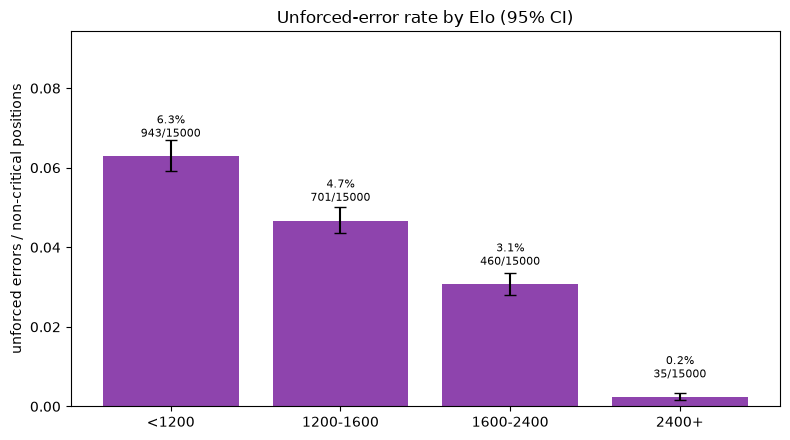

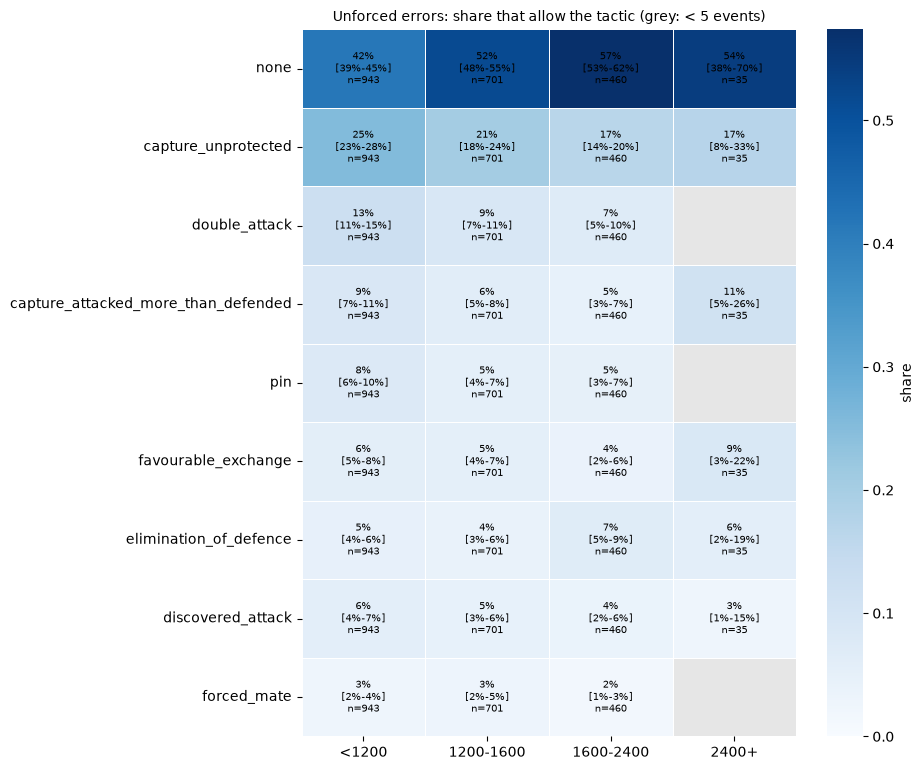

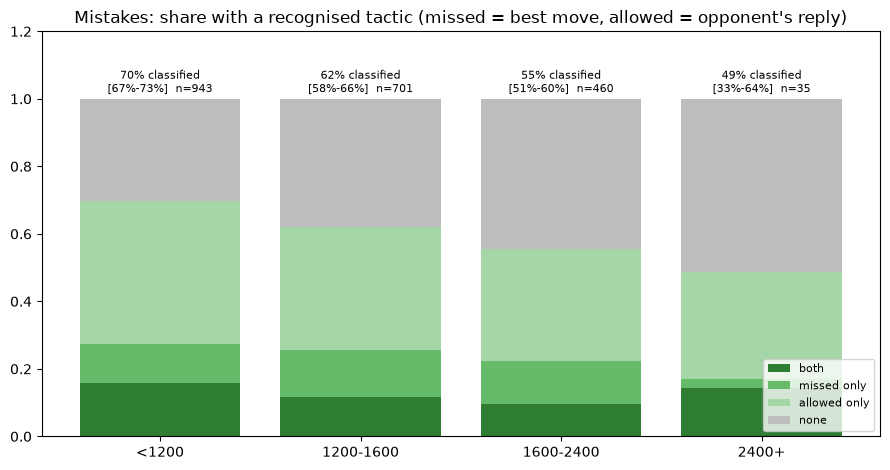

In [12]:
uf = pd.read_csv(UNFORCED)
print(f"{len(uf)} non-critical positions, {int((uf['is_unforced_error'].astype(str).str.lower() == 'true').sum())} unforced errors")
display(S.unforced_rate_table(uf, BINS, LABELS).round(3))
S.plot_unforced_rate(uf, BINS, LABELS); plt.show()

errors = uf[uf['is_unforced_error'].astype(str).str.lower() == 'true']
S.plot_share_heatmap(errors, BINS, LABELS, 'allowed_tactics', title='Unforced errors: share that allow the tactic', min_n=5); plt.show()
S.plot_classified_share(errors.assign(found_best=False), BINS, LABELS); plt.show()

## 8. Extra analyses 
**coverage** against the 80% target, **tactic length**, **co-occurrence** of tactics, and **critical mistakes vs unforced errors**.

In [13]:
import tactic_report as R
importlib.reload(R)

unf = R.load_unforced(UNFORCED)
errs = unf[unf['is_unforced_error']]
print(f"{len(data)} critical positions ({(~data['found_best']).sum()} mistakes), "
      f"{len(unf)} non-critical positions ({len(errs)} unforced errors)")

7318 critical positions (1123 mistakes), 60000 non-critical positions (2139 unforced errors)


### 8a. Tactic length (needs `tactic_length`, see section 4b)

,len_group,n,total,share,ci_low,ci_high
0,0,301,4969,0.061,0.054,0.068
1,1,3910,4969,0.787,0.775,0.798
2,2,561,4969,0.113,0.104,0.122
3,3+,197,4969,0.040,0.035,0.045


,len_group,n_critical,n_found,found_rate,blunder_rate,ci_low,ci_high,blunder_ci_low,blunder_ci_high
0,0,301,205,0.681,0.319,0.626,0.731,0.269,0.374
1,1,3910,3452,0.883,0.117,0.872,0.893,0.107,0.128
2,2,561,406,0.724,0.276,0.685,0.759,0.241,0.315
3,3+,197,138,0.701,0.299,0.633,0.760,0.240,0.367


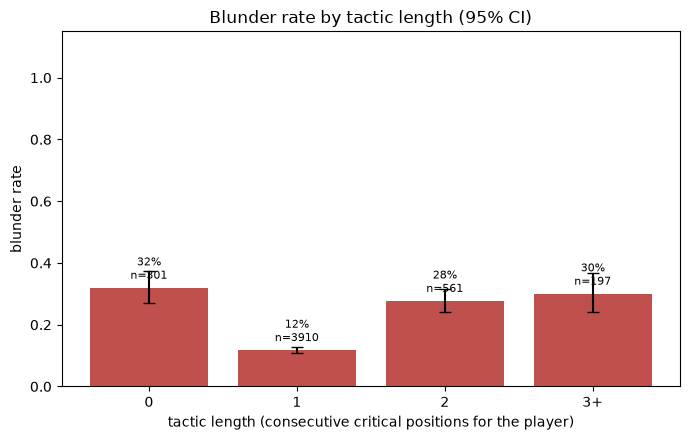

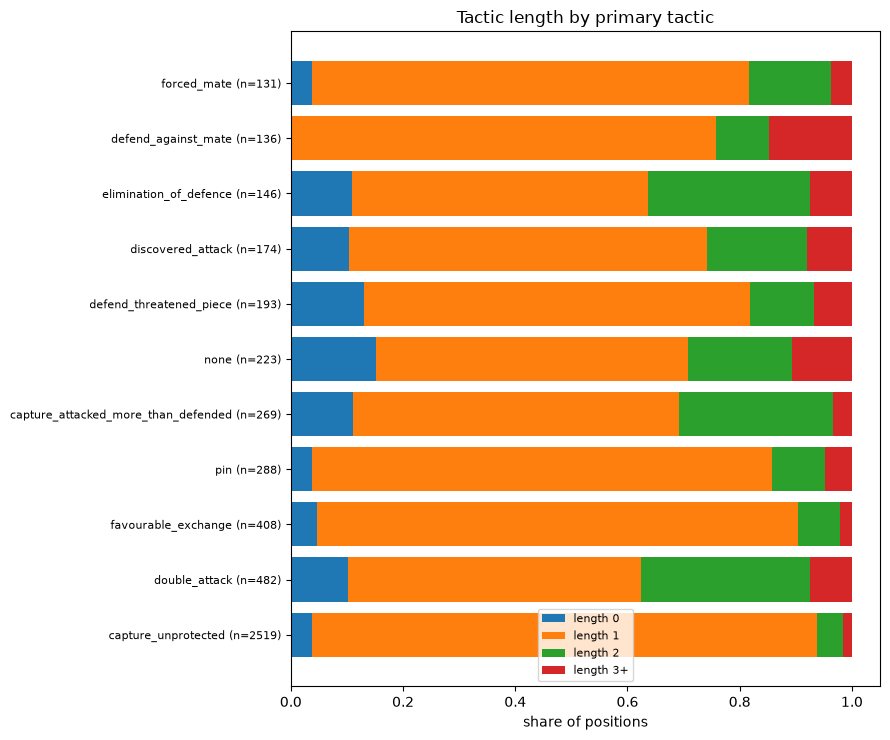

In [15]:
if 'tactic_length' in data.columns and data['tactic_length'].notna().any():
    display(R.length_distribution(data).round(3))
    display(R.blunder_by_length(data).round(3))
    R.plot_blunder_by_length(data); plt.show()
    R.plot_length_distribution(data, by='missed_primary'); plt.show()
else:
    print("no tactic_length yet - run section 4b first")

### 8c. Co-occurrence: which tactics appear together in one best move
One move can realise several tactics (e.g. a fork that is also a discovered attack). A high value between two tactics suggests overlapping definitions.

,capture_attacked_more_than_defended,capture_unprotected,defend_against_mate,defend_threatened_piece,discovered_attack,double_attack,elimination_of_defence,favourable_exchange,forced_mate,pin
capture_attacked_more_than_defended,328,0,3,0,4,33,12,0,15,10
capture_unprotected,0,3007,42,0,48,163,67,0,27,212
defend_against_mate,3,42,138,1,2,2,3,9,2,1
defend_threatened_piece,0,0,1,221,5,14,3,0,2,5
discovered_attack,4,48,2,5,195,11,12,20,6,5
double_attack,33,163,2,14,11,512,46,3,29,44
elimination_of_defence,12,67,3,3,12,46,213,11,3,13
favourable_exchange,0,0,9,0,20,3,11,451,1,0
forced_mate,15,27,2,2,6,29,3,1,131,8
pin,10,212,1,5,5,44,13,0,8,340


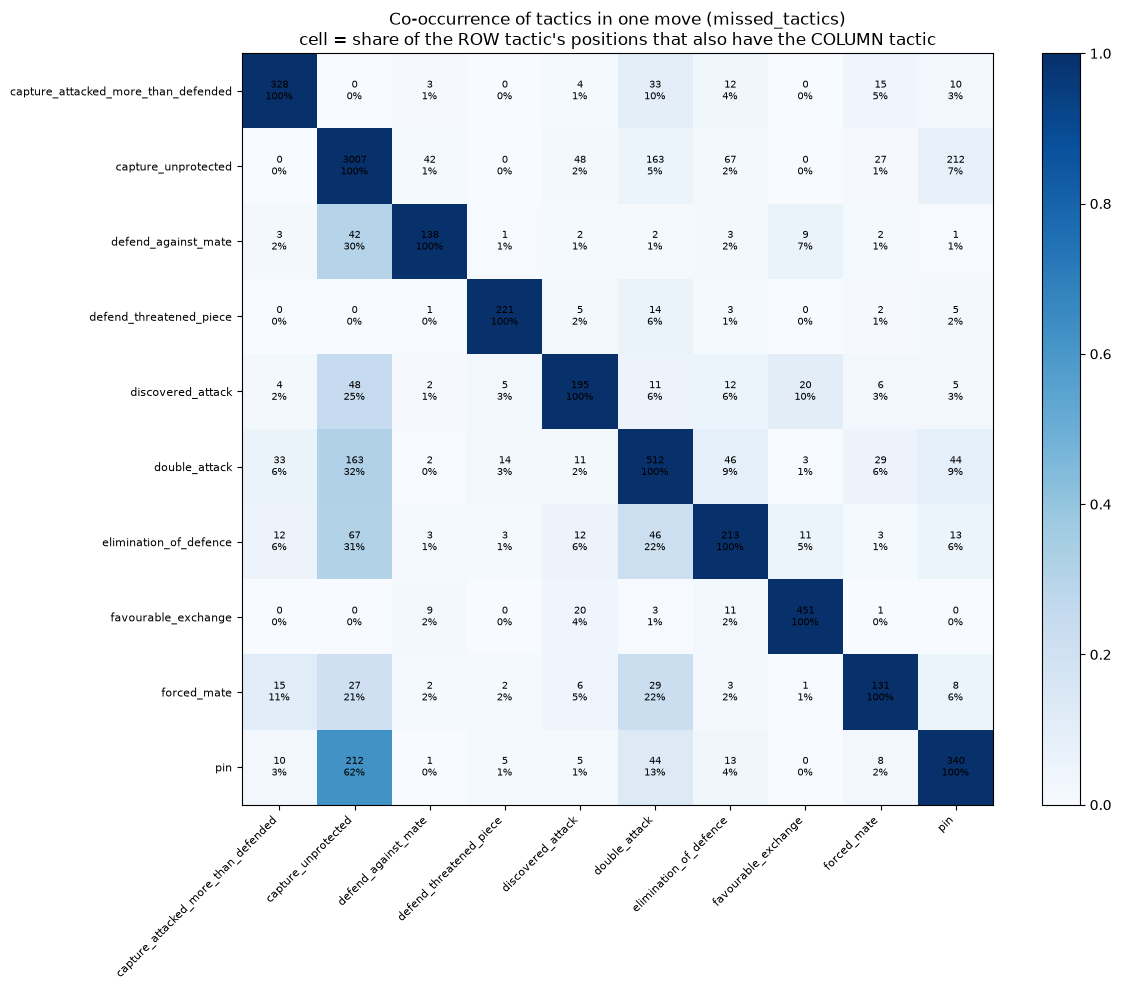

,combo,n,n_found,n_tactics,share,share_ci_low,share_ci_high,blunder_rate,blunder_ci_low,blunder_ci_high
0,none,2572,1994,0,0.351,0.341,0.362,0.225,0.209,0.241
1,capture_unprotected,2519,2380,1,0.344,0.333,0.355,0.055,0.047,0.065
2,favourable_exchange,408,373,1,0.056,0.051,0.061,0.086,0.062,0.117
3,capture_attacked_more_than_defended,269,219,1,0.037,0.033,0.041,0.186,0.144,0.237
4,double_attack,246,180,1,0.034,0.030,0.038,0.268,0.217,0.327
5,defend_threatened_piece,193,141,1,0.026,0.023,0.030,0.269,0.212,0.336
6,capture_unprotected;pin,185,169,2,0.025,0.022,0.029,0.086,0.054,0.136
7,capture_unprotected;double_attack,113,100,2,0.015,0.013,0.019,0.115,0.068,0.187
8,discovered_attack,99,66,1,0.014,0.011,0.016,0.333,0.248,0.431
9,elimination_of_defence,94,66,1,0.013,0.011,0.016,0.298,0.215,0.397


In [16]:
display(R.cooccurrence_matrix(data, 'missed_tactics'))
R.plot_cooccurrence(data, 'missed_tactics', normalise=True); plt.show()
display(R.combination_table(data, 'missed_tactics', min_n=5).round(3))

### 8d. Mistakes in critical positions vs unforced errors
Do the two kinds of errors allow / miss the same tactics?

,allowed_crit_n,allowed_crit_share,allowed_crit_ci_low,allowed_crit_ci_high,allowed_unf_n,allowed_unf_share,allowed_unf_ci_low,allowed_unf_ci_high,missed_crit_n,missed_crit_share,missed_crit_ci_low,missed_crit_ci_high,missed_unf_n,missed_unf_share,missed_unf_ci_low,missed_unf_ci_high
tactic,,,,,,,,,,,,,,,,
capture_attacked_more_than_defended,57.0,0.051,0.039,0.065,154.0,0.072,0.062,0.084,64,0.057,0.045,0.072,47.0,0.022,0.017,0.029
capture_unprotected,197.0,0.175,0.154,0.199,467.0,0.218,0.201,0.236,186,0.166,0.145,0.189,124.0,0.058,0.049,0.069
defend_against_mate,0.0,0.000,0.000,0.000,0.0,0.000,0.000,0.000,9,0.008,0.004,0.015,0.0,0.000,0.000,0.000
defend_threatened_piece,0.0,0.000,0.000,0.000,0.0,0.000,0.000,0.000,61,0.054,0.043,0.069,155.0,0.072,0.062,0.084
discovered_attack,29.0,0.026,0.018,0.037,104.0,0.049,0.040,0.059,49,0.044,0.033,0.057,59.0,0.028,0.021,0.035
double_attack,85.0,0.076,0.062,0.093,217.0,0.101,0.089,0.115,118,0.105,0.088,0.124,82.0,0.038,0.031,0.047
elimination_of_defence,39.0,0.035,0.026,0.047,107.0,0.050,0.042,0.060,44,0.039,0.029,0.052,0.0,0.000,0.000,0.000
favourable_exchange,31.0,0.028,0.020,0.039,115.0,0.054,0.045,0.064,40,0.036,0.026,0.048,20.0,0.009,0.006,0.014
forced_mate,48.0,0.043,0.032,0.056,54.0,0.025,0.019,0.033,35,0.031,0.022,0.043,12.0,0.006,0.003,0.010


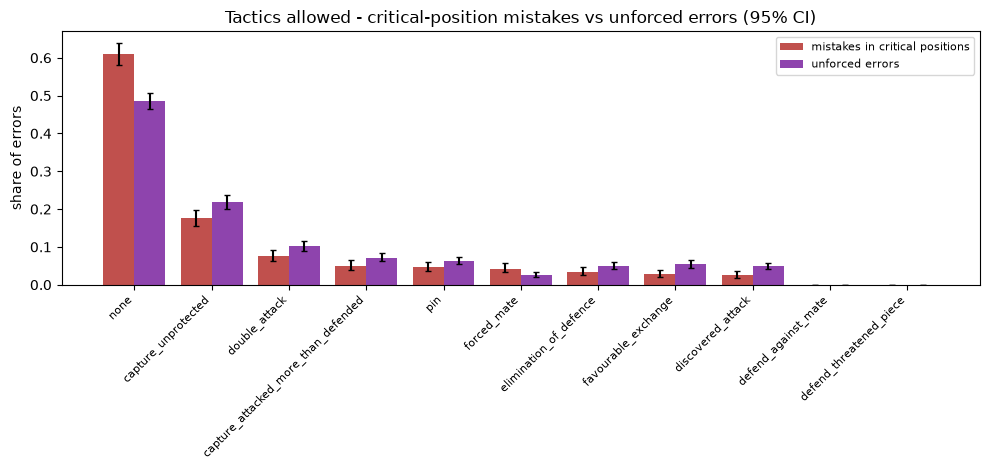

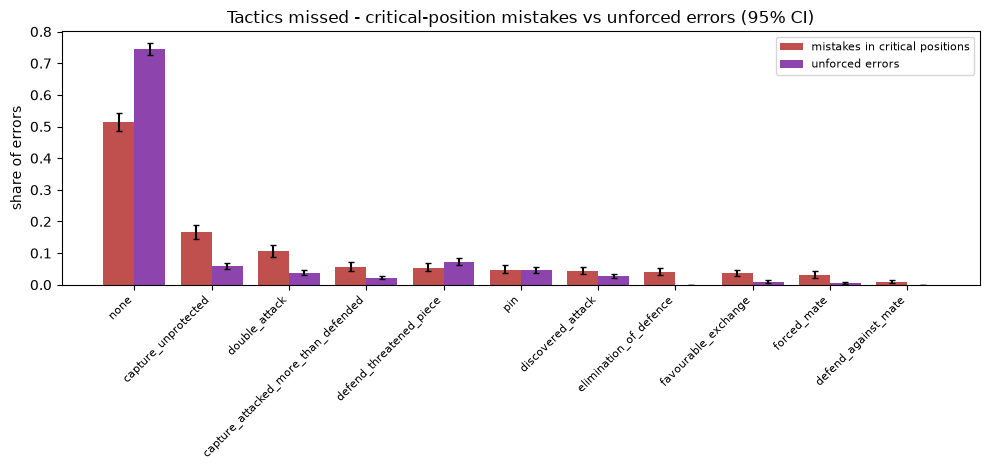

In [17]:
display(R.compare_error_types(data, unf).round(3))
R.plot_compare_error_types(data, unf, kind='allowed'); plt.show()
R.plot_compare_error_types(data, unf, kind='missed'); plt.show()